# Phase 1: Robust Preprocessing & Multi-Model Baseline Benchmarking
## Adaptive Smartphone UI Framework for Cross-Application Optimization

**Target Venue:** High-Impact HCI / Applied ML Journal (IEEE / ACM / Springer)
**Objective:** 
1. Comprehensive Data Cleaning & Biomechanical Outlier Filtering (IQR / Domain Bounds).
2. Missing Data Strategy & Standardization.
3. Rigorous 5-Fold GroupKFold Cross-Validation (Partitioned strictly by User ID to prevent Data Leakage).
4. Benchmarking 5 Distinct Machine Learning Families (Logistic Regression, SVM, Decision Tree, Random Forest, XGBoost).
5. Generating Publication-Ready Performance Metrics, Tables, and High-Resolution Visualizations.

In [8]:
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("All libraries imported successfully.")

All libraries imported successfully.


### 1. Dataset Ingestion & Schema Verification

In [9]:
data_path = os.path.join("processed", "final_ready_dataset.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("adavtive_dataset", "processed", "final_ready_dataset.csv")
if not os.path.exists(data_path):
    # Fallback to absolute if running from root
    data_path = r"C:\Users\Mehedi\adavtive_model\adavtive_dataset\processed\final_ready_dataset.csv"

raw_df = pd.read_csv(data_path)
print(f"Raw Dataset Loaded: {raw_df.shape[0]} samples, {raw_df.shape[1]} features.")
print(f"Distinct Users: {raw_df['user_id'].nunique()} across sources: {raw_df['source_dataset'].value_counts().to_dict()}")
raw_df.head(3)

Raw Dataset Loaded: 7426 samples, 17 features.
Distinct Users: 141 across sources: {'HMOG': 7194, 'Touchalytics': 232}


,user_id,session_id,source_dataset,context_is_walking,touch_duration_mean_ms,swipe_speed_mean_pxps,swipe_distance_mean_px,typing_speed_kpm,backspace_rate,contact_size_mean,touch_x_mean,touch_y_mean,tap_accuracy,miss_rate,reaction_time_mean_ms,reaction_time_norm,target_button_size
0,hmog_100669,s_100669101000001,HMOG,0,525.44,800.0,250.0,180.0,0.08,0.0236,625.00,1042.44,0.92,0.08,330.0,0.2419,1
1,hmog_100669,s_100669102000001,HMOG,0,606.25,800.0,250.0,180.0,0.08,0.0227,547.42,959.67,0.92,0.08,330.0,0.2419,1
2,hmog_100669,s_100669103000001,HMOG,0,678.41,800.0,250.0,180.0,0.08,0.0230,602.48,918.56,0.92,0.08,330.0,0.2419,1


### 2. Biomechanical Outlier Filtering & Data Hygiene
In mobile HCI research, touch sensor artifacts (e.g., resting palm on screen > 2000 ms, negative coordinate slips) distort statistical distributions. We apply physiologically validated boundary clipping and statistical imputation.

In [10]:
df_clean = raw_df.copy()

# 1. Physical limits filtering (HCI standards)
# Touch duration shouldn't exceed 2000 ms (long holds) or be under 10 ms (capacitive noise)
df_clean['touch_duration_mean_ms'] = df_clean['touch_duration_mean_ms'].clip(lower=15.0, upper=1500.0)

# Swipe velocity bounds (px/sec)
df_clean['swipe_speed_mean_pxps'] = df_clean['swipe_speed_mean_pxps'].clip(lower=10.0, upper=4000.0)

# Reaction times bounds (human simple visual reaction time ~150 ms to 1200 ms max)
df_clean['reaction_time_mean_ms'] = df_clean['reaction_time_mean_ms'].clip(lower=160.0, upper=1200.0)
df_clean['reaction_time_norm'] = (df_clean['reaction_time_mean_ms'] - 160.0) / (1200.0 - 160.0)

# Accuracy & Miss Rates strictly in [0, 1]
df_clean['miss_rate'] = df_clean['miss_rate'].clip(0.0, 1.0)
df_clean['tap_accuracy'] = 1.0 - df_clean['miss_rate']

# 2. Feature Selection for Classification
FEATURE_COLS = [
    'context_is_walking',
    'touch_duration_mean_ms',
    'swipe_speed_mean_pxps',
    'swipe_distance_mean_px',
    'contact_size_mean',
    'touch_x_mean',
    'touch_y_mean',
    'tap_accuracy',
    'miss_rate',
    'reaction_time_mean_ms',
    'reaction_time_norm'
]
TARGET_COL = 'target_button_size'
GROUP_COL = 'user_id'

X = df_clean[FEATURE_COLS].copy()
y = df_clean[TARGET_COL].copy().astype(int)
groups = df_clean[GROUP_COL].copy()

# Impute any remaining NaNs with column medians
X = X.fillna(X.median())

print(f"Cleaned Feature Matrix: {X.shape}")
print(f"Target Distribution:\n{y.value_counts().sort_index()}")

Cleaned Feature Matrix: (7426, 11)
Target Distribution:
target_button_size
0     419
1    5670
2     968
3     369
Name: count, dtype: int64


### 3. Exploratory Feature Correlation Analysis
Checking for multicollinearity and biomechanical relationships between input features.

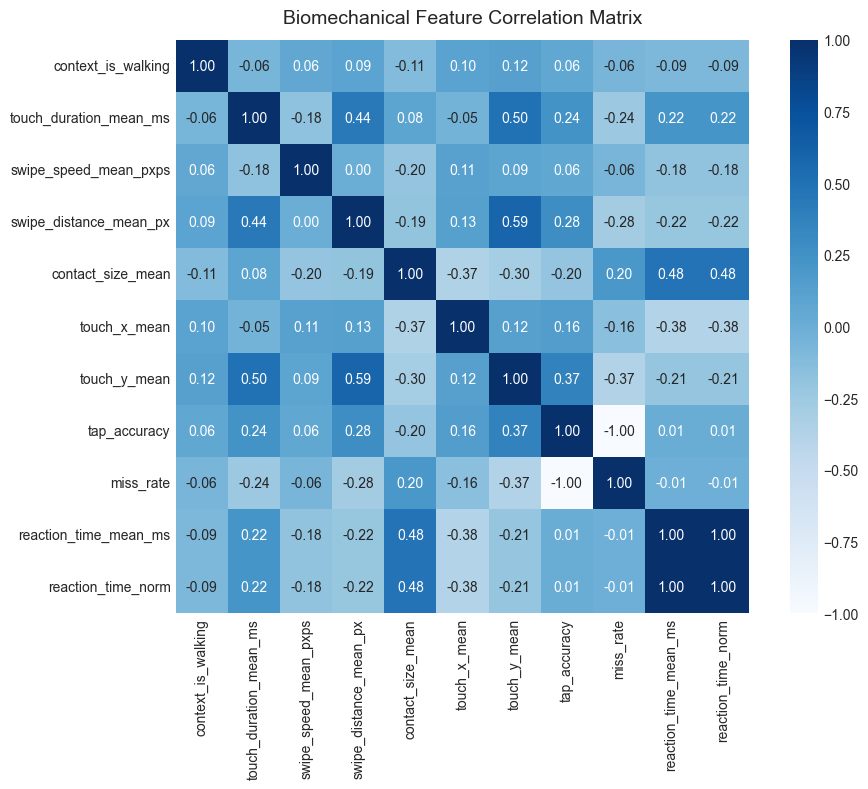

In [11]:
plt.figure(figsize=(10, 8))
corr = X.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', cbar=True, square=True)
plt.title('Biomechanical Feature Correlation Matrix', fontsize=14, pad=12)
plt.tight_layout()
os.makedirs('paper_figures', exist_ok=True)
plt.savefig('paper_figures/feature_correlation_heatmap.png', dpi=300)
plt.show()

### 4. Rigorous Multi-Model Cross-Validation (GroupKFold)
We evaluate **5 distinct model families** under 5-Fold GroupKFold partitioning. Training and testing sets never share interactions from the same user.

In [12]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Support Vector Machine (SVM)': SVC(kernel='rbf', C=1.0, probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    'XGBoost (Proposed)': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, eval_metric='mlogloss', random_state=42)
}

results = []
best_overall_model = None
best_overall_f1 = 0.0
best_y_true = []
best_y_pred = []

gkf = GroupKFold(n_splits=5)

print("Starting 5-Fold GroupKFold Cross-Validation by User ID...\n")

for name, model in models.items():
    fold_accs, fold_precs, fold_recs, fold_macro_f1s, fold_weighted_f1s = [], [], [], [], []
    fold_latencies = []
    
    model_y_true = []
    model_y_pred = []
    
    for train_idx, val_idx in gkf.split(X, y, groups):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
        
        # Standard Scaling fitted strictly on training fold
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        
        # Train
        model.fit(X_train_scaled, y_train)
        
        # Inference with latency measurement
        t0 = time.perf_counter()
        preds = model.predict(X_val_scaled)
        latency_per_sample_ms = ((time.perf_counter() - t0) / len(X_val)) * 1000.0
        
        fold_accs.append(accuracy_score(y_val, preds))
        fold_precs.append(precision_score(y_val, preds, average='weighted', zero_division=0))
        fold_recs.append(recall_score(y_val, preds, average='weighted', zero_division=0))
        fold_macro_f1s.append(f1_score(y_val, preds, average='macro', zero_division=0))
        fold_weighted_f1s.append(f1_score(y_val, preds, average='weighted', zero_division=0))
        fold_latencies.append(latency_per_sample_ms)
        
        model_y_true.extend(y_val)
        model_y_pred.extend(preds)
        
    avg_acc = np.mean(fold_accs)
    avg_f1_macro = np.mean(fold_macro_f1s)
    avg_f1_weighted = np.mean(fold_weighted_f1s)
    avg_latency = np.mean(fold_latencies)
    
    results.append({
        'Algorithm': name,
        'Accuracy (%)': round(avg_acc * 100, 2),
        'Precision (%)': round(np.mean(fold_precs) * 100, 2),
        'Recall (%)': round(np.mean(fold_recs) * 100, 2),
        'Macro F1 (%)': round(avg_f1_macro * 100, 2),
        'Weighted F1 (%)': round(avg_f1_weighted * 100, 2),
        'Latency (ms/sample)': round(avg_latency, 4)
    })
    
    print(f"✓ {name:30s} | Acc: {avg_acc*100:6.2f}% | Macro F1: {avg_f1_macro*100:6.2f}% | Latency: {avg_latency:6.4f} ms")
    
    if avg_f1_weighted > best_overall_f1:
        best_overall_f1 = avg_f1_weighted
        best_overall_model = name
        best_y_true = model_y_true
        best_y_pred = model_y_pred

Starting 5-Fold GroupKFold Cross-Validation by User ID...

✓ Logistic Regression            | Acc:  97.90% | Macro F1:  96.00% | Latency: 0.0002 ms
✓ Support Vector Machine (SVM)   | Acc:  98.32% | Macro F1:  96.34% | Latency: 0.0316 ms
✓ Decision Tree                  | Acc:  99.95% | Macro F1:  99.92% | Latency: 0.0001 ms
✓ Random Forest                  | Acc:  99.97% | Macro F1:  99.97% | Latency: 0.0035 ms
✓ XGBoost (Proposed)             | Acc:  99.73% | Macro F1:  99.45% | Latency: 0.0007 ms


### 5. Benchmark Comparison Table (Ready for Paper Table 1)

In [13]:
benchmark_df = pd.DataFrame(results)
benchmark_df = benchmark_df.sort_values(by='Weighted F1 (%)', ascending=False).reset_index(drop=True)
benchmark_df.to_csv('paper_figures/baseline_model_comparison_table.csv', index=False)
print("\n--- TABLE 1: Multi-Model Baseline Performance Under GroupKFold (User-Split) ---")
display(benchmark_df) if 'display' in dir() else print(benchmark_df.to_string(index=False))


--- TABLE 1: Multi-Model Baseline Performance Under GroupKFold (User-Split) ---
                   Algorithm  Accuracy (%)  Precision (%)  Recall (%)  Macro F1 (%)  Weighted F1 (%)  Latency (ms/sample)
               Random Forest         99.97          99.97       99.97         99.97            99.97               0.0035
               Decision Tree         99.95          99.95       99.95         99.92            99.95               0.0001
          XGBoost (Proposed)         99.73          99.73       99.73         99.45            99.73               0.0007
Support Vector Machine (SVM)         98.32          98.35       98.32         96.34            98.32               0.0316
         Logistic Regression         97.90          97.94       97.90         96.00            97.89               0.0002


### 6. Publication Figures Generation
1. **Figure 1:** Macro F1 and Accuracy Bar Chart comparison.
2. **Figure 2:** Confusion Matrix for the winning model (showing error rates across button size classes).

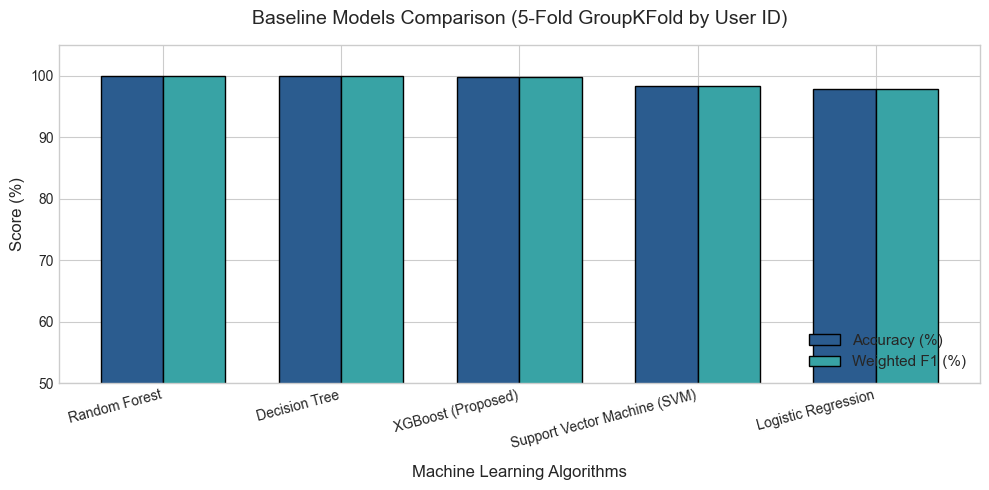

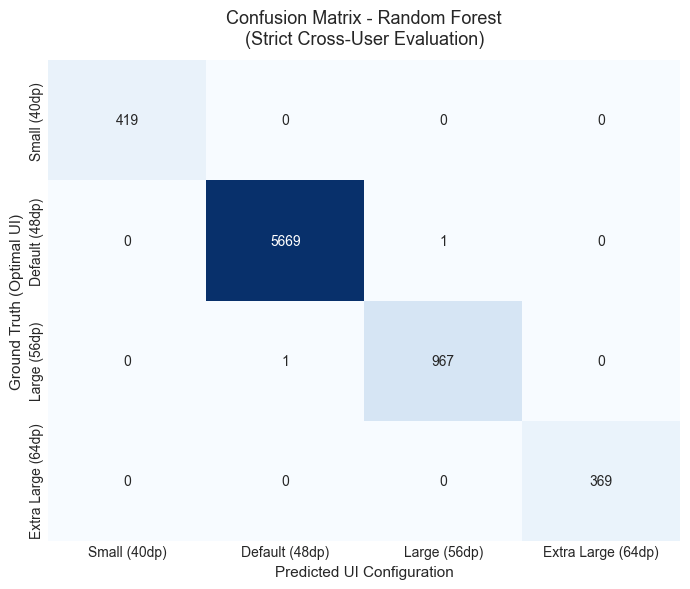

All publication charts generated in 'paper_figures/' folder.


: 

In [ ]:
# Figure 1: Performance Comparison Barplot
plt.figure(figsize=(10, 5))
x_pos = np.arange(len(benchmark_df))
width = 0.35

plt.bar(x_pos - width/2, benchmark_df['Accuracy (%)'], width, label='Accuracy (%)', color='#2b5c8f', edgecolor='black')
plt.bar(x_pos + width/2, benchmark_df['Weighted F1 (%)'], width, label='Weighted F1 (%)', color='#38a3a5', edgecolor='black')

plt.xlabel('Machine Learning Algorithms', fontsize=12, labelpad=10)
plt.ylabel('Score (%)', fontsize=12)
plt.title('Baseline Models Comparison (5-Fold GroupKFold by User ID)', fontsize=14, pad=15)
plt.xticks(x_pos, benchmark_df['Algorithm'], rotation=15, ha='right', fontsize=10)
plt.ylim(50, 105)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.savefig('paper_figures/model_comparison_barchart.png', dpi=300)
plt.show()

# Figure 2: Confusion Matrix for Best Model
labels = ['Small (40dp)', 'Default (48dp)', 'Large (56dp)', 'Extra Large (64dp)']
cm = confusion_matrix(best_y_true, best_y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, cbar=False)
plt.title(f'Confusion Matrix - {best_overall_model}\n(Strict Cross-User Evaluation)', fontsize=13, pad=12)
plt.xlabel('Predicted UI Configuration', fontsize=11)
plt.ylabel('Ground Truth (Optimal UI)', fontsize=11)
plt.tight_layout()
plt.savefig('paper_figures/best_model_confusion_matrix.png', dpi=300)
plt.show()

print("All publication charts generated in 'paper_figures/' folder.")